# BrushCue Example: Quiet Window

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/quiet_window.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/quiet-window

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


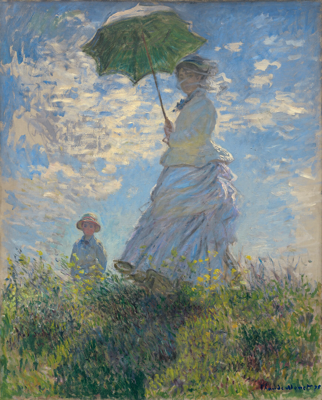

In [1]:
import io
from PIL import Image

import brushcue as bc


@bc.brushcue_fn
def apply(input_image, strength):
    graded = input_image.color_transformer_shader(
        "let l = clamp(input.x, 0.0, 1.0);\nlet shade = 1.0 - smoothstep(0.18, 0.65, l);\nlet light = smoothstep(0.55, 0.96, l);\nlet blue = smoothstep(0.005, 0.08, -input.z) * smoothstep(0.01, 0.07, length(input.yz));\nlet tone = l + 0.028 * sin(l * 3.14159265) - 0.025 * light * light;\nlet ab = input.yz * (0.91 + 0.13 * blue) + vec2f(-0.006, -0.014) * shade + vec2f(0.001, 0.018) * light;\nreturn vec4f(mix(input.xyz, vec3f(tone, ab), amount), input.w);",
        "",
        bc.ColorRepresentation.oklab_a(),
        bc.ColorRepresentation.oklab_a(),
        bc.Dictionary.create().add("amount", strength),
    )
    bounds = input_image.bounds()
    return graded.crop(bounds)


strength = 1.0
input_image = bc.Composition.monet_women_with_parasol()
graph = apply(input_image, strength)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
